In [ ]:
import numpy as np
import matplotlib.pyplot as plt

CSV_PATH = "banknote.csv"   
EPOCHS = 3000
LR = 0.5                    
TEST_SIZE = 0.25

W1_INIT = np.array([[0.21, -0.35, 0.12, 0.40],
                    [0.24, 0.56, -0.18, 0.09],
                    [0.30, -0.15, -0.33, 0.22],
                    [-0.27, 0.41, 0.08, -0.19]])
B1_INIT = np.array([[0.20, 0.05, -0.05, 0.10]])
W2_INIT = np.array([[0.60], [-0.45], [0.32], [-0.21]])
B2_INIT = np.array([[0.10]])

In [ ]:
def load_data(path=CSV_PATH):
    d = np.genfromtxt(path, delimiter=",")
    d = d[~np.isnan(d).any(axis=1)]          
    return d[:, :4], d[:, 4:5]


def split(X, y):
    rng = np.random.default_rng(0)
    tr, te = [], []
    for c in np.unique(y):
        i = np.where(y.ravel() == c)[0]
        rng.shuffle(i)
        k = int(round(len(i) * TEST_SIZE))
        te += list(i[:k])
        tr += list(i[k:])
    tr, te = np.array(tr), np.array(te)
    rng.shuffle(tr)
    rng.shuffle(te)
    mu, sd = X[tr].mean(axis=0), X[tr].std(axis=0)
    return (X[tr] - mu) / sd, y[tr], (X[te] - mu) / sd, y[te]


X, y = load_data()
Xtr, ytr, Xte, yte = split(X, y)
print(f"train: {len(Xtr)}, test: {len(Xte)}")

train: 1030, test: 342


Forward propagation

$$F = \sin(X),\quad A_1 = \sigma(F W_1 + b_1),\quad \hat y = \sigma(A_1 W_2 + b_2)$$

In [ ]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp)


def phi(X):
    """Functional expansion: phi(x) = sin(x)."""
    return np.sin(X)


def init_params():
    return [W1_INIT.copy(), B1_INIT.copy(), W2_INIT.copy(), B2_INIT.copy()]


def forward(X, P, expand=True):
    F = phi(X) if expand else X
    A1 = sigmoid(F @ P[0] + P[1])      
    yh = sigmoid(A1 @ P[2] + P[3])     
    return F, A1, yh


def mse(yh, y):
    return float(np.mean((yh - y) ** 2))


def accuracy(yh, y):
    return float(np.mean((yh > 0.5) == (y > 0.5)))

Backpropagation and weight update

For the MSE loss $L=\frac1N\sum(\hat y-y)^2$:

$$\delta_2 = \frac{2}{N}(\hat y-y)\,\hat y(1-\hat y),\qquad
\delta_1 = (\delta_2 W_2^T)\odot A_1(1-A_1)$$

$$\nabla W_2 = A_1^T\delta_2,\ \nabla b_2=\sum\delta_2,\ \nabla W_1 = F^T\delta_1,\ \nabla b_1=\sum\delta_1$$

Gradient descent update: $\theta \leftarrow \theta - \eta\,\nabla\theta$.

In [ ]:
def backward(X, y, P, expand=True):
    F, A1, yh = forward(X, P, expand)
    n = len(y)
    dZ2 = 2.0 * (yh - y) / n * yh * (1 - yh)     
    dZ1 = (dZ2 @ P[2].T) * A1 * (1 - A1)         
    return [F.T @ dZ1, dZ1.sum(axis=0, keepdims=True),
            A1.T @ dZ2, dZ2.sum(axis=0, keepdims=True)]


def train(X, y, expand=True):
    P = init_params()
    loss = []
    for _ in range(EPOCHS):
        loss.append(mse(forward(X, P, expand)[-1], y))
        G = backward(X, y, P, expand)
        P = [p - LR * g for p, g in zip(P, G)]
    return P, loss


def gradient_check(expand=True, eps=1e-6):
    rng = np.random.default_rng(0)
    Xc = rng.normal(size=(8, 4))
    yc = (rng.random((8, 1)) > 0.5).astype(float)
    P = init_params()
    G = backward(Xc, yc, P, expand)
    worst = 0.0
    for p, g in zip(P, G):
        for i in np.ndindex(p.shape):
            old = p[i]
            p[i] = old + eps
            lp = mse(forward(Xc, P, expand)[-1], yc)
            p[i] = old - eps
            lm = mse(forward(Xc, P, expand)[-1], yc)
            p[i] = old
            worst = max(worst, abs((lp - lm) / (2 * eps) - g[i]))
    return worst


print(f"gradient check (max error): {gradient_check():.2e}")

gradient check (max error): 4.04e-11


In [5]:
P, loss = train(Xtr, ytr, expand=True)
P_no, loss_no = train(Xtr, ytr, expand=False)

p_te = forward(Xte, P)[-1]
p_te_no = forward(Xte, P_no, expand=False)[-1]

print(f"{'':22s}{'MSE train':>12s}{'MSE test':>12s}{'Acc test':>12s}")
print(f"{'with sin expansion':22s}{loss[-1]:12.5f}{mse(p_te, yte):12.5f}{accuracy(p_te, yte):12.4f}")
print(f"{'without expansion':22s}{loss_no[-1]:12.5f}{mse(p_te_no, yte):12.5f}{accuracy(p_te_no, yte):12.4f}")

                         MSE train    MSE test    Acc test
with sin expansion         0.02669     0.02508      0.9620
without expansion          0.00886     0.00860      0.9912


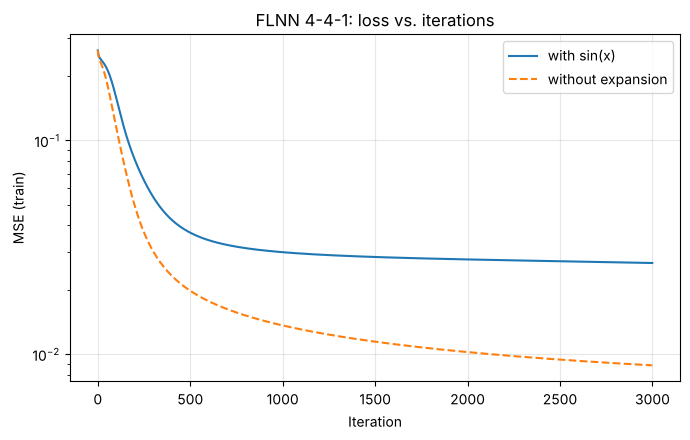

In [6]:
plt.figure(figsize=(7, 4.5))
plt.plot(loss, label="with sin(x)")
plt.plot(loss_no, "--", label="without expansion")
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("MSE (train)")
plt.title("FLNN 4-4-1: loss vs. iterations")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("loss.png", dpi=150)
plt.show()

In [7]:
print(f"{'#':>3s}{'target':>8s}{'predicted':>11s}{'class':>7s}")
for i in range(10):
    print(f"{i + 1:3d}{yte[i, 0]:8.0f}{p_te[i, 0]:11.4f}{int(p_te[i, 0] > 0.5):7d}")

  #  target  predicted  class
  1       1     0.9919      1
  2       0     0.0056      0
  3       0     0.0038      0
  4       1     0.9914      1
  5       1     0.9251      1
  6       1     0.9539      1
  7       1     0.9265      1
  8       1     0.9851      1
  9       1     0.8325      1
 10       0     0.0126      0
